### **Exploratory Data Analysis (EDA) with Sales Dataset using Pandas and Matplotlib/Seaborn**

### **Objective:**
##### This project demonstrates Exploratory Data Analysis (EDA) on online retail sales data using Python. Data was imported from Excel and integrated across multiple tables (Sales, Invoice and Product), then cleaned, merged and transformed using Pandas. Insights were communicated through Matplotlib and Seaborn visualisations to identify trends, outliers, distributions and correlations.


###  **Dataset**

##### The dataset represents transaction data from a retail business, specifically sales data for products sold in various stores. It contains multiple tables that provide insights into sales, invoices, and products. Let’s break down the tables and what they represent:

#### **Sales Table:**

##### InvoiceNo: The unique identifier for each invoice (or transaction).

##### StockCode: A unique identifier for each product.

##### Quantity: The number of units sold in each transaction.

##### UnitPrice: The price per unit of the product.

##### InvoiceDate: The date when the transaction occurred.

#### **Invoice Table:**

##### InvoiceNo: The same unique identifier for each invoice, linking the sales data with the invoice details.

##### Country: The country where the sale was made.

#### **Product Table:**

##### StockCode: A unique identifier for each product.

##### Description: The name or description of the product.

##### Product_Category: The category the product belongs to (e.g., "Gift", "Sign", "Mug").
##### You will need to merge them and perform the following tasks step by step.


#### **1.Load the Excel File**
#### Objective: Import the data from the provided Excel file into Python using Pandas.

In [1]:
import pandas as pd

import pandas as pd

import pandas as pd

df_sales = pd.read_excel(f"{notebookutils.nbResPath}/builtin/Online Sales Retailer 1.xlsx", sheet_name= 'Sales')

df_invoice = pd.read_excel(f"{notebookutils.nbResPath}/builtin/Online Sales Retailer 1.xlsx", sheet_name= 'Invoice')

df_product = pd.read_excel(f"{notebookutils.nbResPath}/builtin/Online Sales Retailer 1.xlsx", sheet_name= 'Product')

# Display the first few rows of each Dataframe
display(df_sales.head())
display(df_invoice.head())
display(df_product.head())


#### **2. Basic Python and Pandas Operations**
#### Objective: Perform basic Python and Pandas operations to manipulate the data.

In [2]:
# Checking the column names before start coding
df_sales.columns

Index(['InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice', 'InvoiceDate'], dtype='object')

In [3]:
## Creating new column called Sales (QTY*Price) in the Sales Table
df_sales['Sales']=df_sales['Quantity'] * df_sales['UnitPrice']

# Display Sales table to check if the code above is applied correctly
display (df_sales)

In [4]:
# This is to count or sum up how many null values in the sales dataframe
df_sales.isna().sum() # the results shows there is no null values in sales df

InvoiceNo      0
StockCode      0
Quantity       0
UnitPrice      0
InvoiceDate    0
Sales          0
dtype: int64

In [5]:
# Check for missing values in Sales DF even though the result above showing no result for null values. This is to validated the result above
missing_values = df_sales.isnull()
# Display only rows with null values
rows_with_nulls = df_sales[missing_values.any(axis=1)]
display(rows_with_nulls) # no null values to replace 

In [6]:
# Checking the total rows of dataset as the displayed sales df only showed 1,000 rows max.
print(df_sales)

       InvoiceNo  StockCode  Quantity  UnitPrice InvoiceDate  Sales
0         536365      71053         6       3.39  2015-01-01  20.34
1         536365      22752         2       7.65  2015-01-01  15.30
2         536365      84406         8       2.75  2015-01-01  22.00
3         536366      84029         6       3.39  2015-01-01  20.34
4         536366      21730         6       4.25  2015-01-01  25.50
...          ...        ...       ...        ...         ...    ...
83272     564122      21210        12       1.45  2018-12-31  17.40
83273     564122      22773        12       1.25  2018-12-31  15.00
83274     564123      21080        12       0.85  2018-12-31  10.20
83275     564123      21673        12       1.25  2018-12-31  15.00
83276     564123      85174         2       4.95  2018-12-31   9.90

[83277 rows x 6 columns]


In [7]:
# Displaying the zero unit price to check the result after creating sales column, as the displayed df sales rows is up to 1,000 max while the whole dataset has total rows of 83,277
zero_unitprice_rows = df_sales[df_sales['UnitPrice']==0]
display(zero_unitprice_rows)



In [8]:
# Descriptive Statistics for the Quantity and UnitPrice columns (mean, median, mode, standard deviation)
mean_Qty = df_sales['Quantity'].mean()
median_Qty = df_sales['Quantity'].median()
mode_Qty = df_sales['Quantity'].mode().iloc[0]
std_Qty = df_sales['Quantity'].std()

mean_unitprice = df_sales['UnitPrice'].mean()
median_unitprice = df_sales['UnitPrice'].median()
mode_unitprice = df_sales['UnitPrice'].mode().iloc[0]
std_unitprice = df_sales['UnitPrice'].std()


In [9]:
# This is to check if mode has tie numbers
print(df_sales['Quantity'].mode())
print(df_sales['UnitPrice'].mode())

0    1
Name: Quantity, dtype: int64
0    1.25
Name: UnitPrice, dtype: float64


In [10]:
# Display the results
print(f"Quantity - Mean: {mean_Qty}, Median: {median_Qty}, Mode: {mode_Qty}, Std Dev: {std_Qty}")
print(f"UnitPrice - Mean: {mean_unitprice}, Median: {median_unitprice}, Mode: {mode_unitprice}, Std Dev: {std_unitprice}")

Quantity - Mean: 13.610961009642518, Median: 6.0, Mode: 1, Std Dev: 261.57756533207146
UnitPrice - Mean: 3.0835027678710816, Median: 1.95, Mode: 1.25, Std Dev: 5.177652565375899


#### **3. Merging DataFrames**
#### Objective: Merge the Sales, Invoice, and Product tables based on common keys to perform a comprehensive analysis.

In [11]:
# Display the first few rows of each Dataframe 
display(df_sales.head())
display(df_invoice.head())
display(df_product.head())

In [12]:
# Merge Sales and Invoie DataFrame on "InvoiceNo"
df_combined_sales = pd.merge(df_sales, df_invoice, on='InvoiceNo')
# Display the first few rows of the merged Dataframe
display(df_combined_sales.head())

In [13]:
# Merge the combined Sales and Invoice Dataframe with Product Dataframe on "StockCode" 
df_final_combined =pd.merge(df_combined_sales,df_product, on='StockCode')
# Display the first few rows of the final merge dataframe
display(df_final_combined.head())

In [14]:
# Checking the total number of rows after merging sales and Invoice dataframe, to ensure that no missing data.
print(df_final_combined.shape)

(83277, 9)


#### **4. Exploratory Data Analysis (EDA)**
### Objective: Conduct EDA by analysing the data, identifying patterns, trends, and outliers.

In [15]:
## Using describe() to calculate summary statistics
df_final_combined.describe() # the result is crucial as this will be my basis for the vizual analysis.

,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Sales
count,83277.000000,83277.000000,83277.000000,83277.000000,83277,83277.000000
mean,550244.000000,32948.774860,13.610961,3.083503,2016-12-31 00:00:00,23.121043
min,536365.000000,10002.000000,1.000000,0.000000,2015-01-01 00:00:00,0.000000
25%,543304.000000,21843.000000,2.000000,1.250000,2016-01-01 00:00:00,5.000000
50%,550244.000000,22470.000000,6.000000,1.950000,2016-12-31 00:00:00,12.500000
75%,557184.000000,22941.000000,12.000000,3.750000,2017-12-31 00:00:00,19.500000
max,564123.000000,90214.000000,74215.000000,295.000000,2018-12-31 00:00:00,77183.600000
std,8013.381169,22938.831323,261.577565,5.177653,NaN,278.041319


In [16]:
## Importing seaborn matplotlib
!pip install seaborn matplotlib

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

## Filter out sales with Quantity is = to 0
df_filtered = df_final_combined[df_final_combined['Quantity'] > 0 ]
df_filtered ['month_year'] = df_filtered['InvoiceDate'].dt.strftime('%Y-%m')
display(df_filtered)

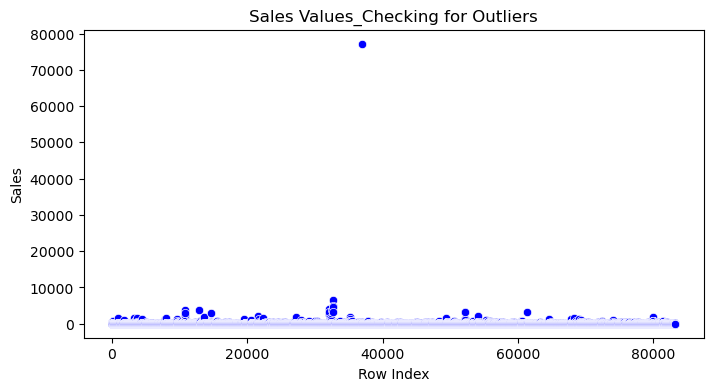

In [18]:
# Checking the outliers in the Sale by using scatter plot
plt.figure(figsize=(8,4))
sns.scatterplot(x=df_filtered.index, y=df_filtered['Sales'], alpha =1, color ='blue')
plt.title('Sales Values_Checking for Outliers')
plt.xlabel('Row Index')
plt.ylabel('Sales')
plt.show()


##### The analysis shows in the scatter plot above, the row index is used as the x-axis simply because it is to spread out each Sales value for visual inspection. The index has no meaning, it is just the row number or position of each sales which makes it easier to spot outliers and which one has most outliers. This appears as point sitting noticeably above the main cluster of data.

In [19]:
# Additional codes used to check the data, ensuring it matches on what the scatter plot is showing
count_high_sales = (df_filtered['Sales'] > 10000).sum()
print("No. of Highest Sales:", count_high_sales)

No. of Highest Sales: 1


In [20]:
# Sorting Sales Data Desc. to understand more and scanned the highest sales
df_sort=df_filtered.sort_values(by='Sales', ascending=False)
display(df_sort)

##### As the result, InvoiceNo 548691 row has the highest Sales total of $77,183.6 which has the highest Quantity Sold.

#### **5. Data Visualisation – Scatter Plot, Histogram, and Line Chart**
#### Objective: Create scatter plots, histograms, and line charts to better understand the data.


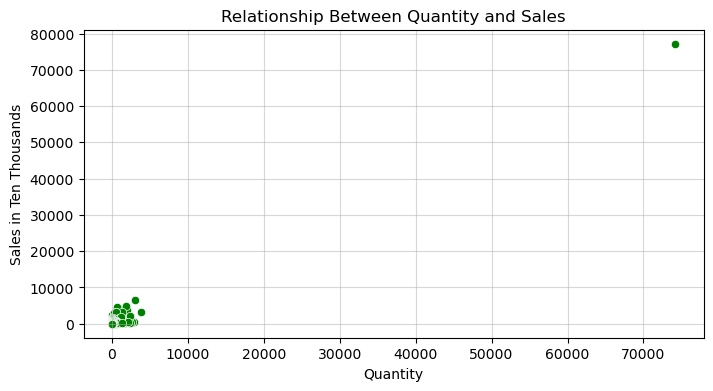

In [21]:
## Scatter plot to visualize the relationship between Quantity and Sales
plt.figure(figsize=(8,4))
sns.scatterplot(x=df_filtered['Quantity'], y=df_filtered['Sales'], alpha =1, color ='green')
plt.title('Relationship Between Quantity and Sales')
plt.xlabel('Quantity')
plt.ylabel('Sales in Ten Thousands')
plt.grid(True, alpha=0.5)
plt.show()


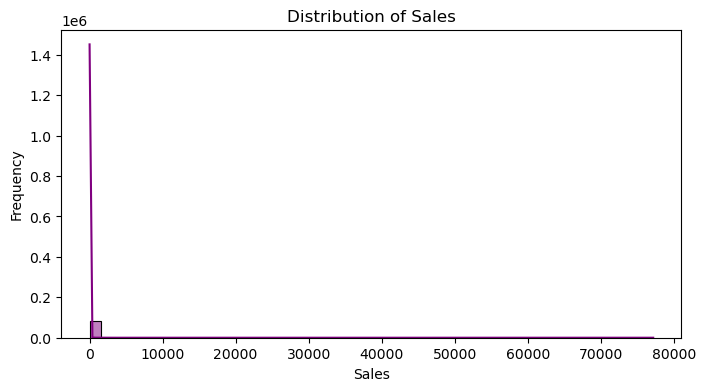

In [22]:
# Histogram to visualize the distribution of sales
plt.figure(figsize=(8,4))
sns.histplot(df_filtered['Sales'], bins=50, color='purple', kde=True)
plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

##### Based on the visual above the frequency has reached up to 1.4M which is misleading in my opinion. The result leads me to do more investigating and validating data to ensure that there are no duplicates created after merging the data frames.

In [23]:
# to double chek if there are duplicate rows created after merging data as the frequency above showed above 1.4M
print("Sales:", df_sales.shape)
print("Combined (Sales+Invoice):", df_combined_sales.shape)
print("Final (Sales+Invoice+Product):", df_final_combined.shape)
print("Filtered:", df_filtered.shape) #Results no duplicate or added rows after merging

Sales: (83277, 6)
Combined (Sales+Invoice): (83277, 7)
Final (Sales+Invoice+Product): (83277, 9)
Filtered: (83277, 10)


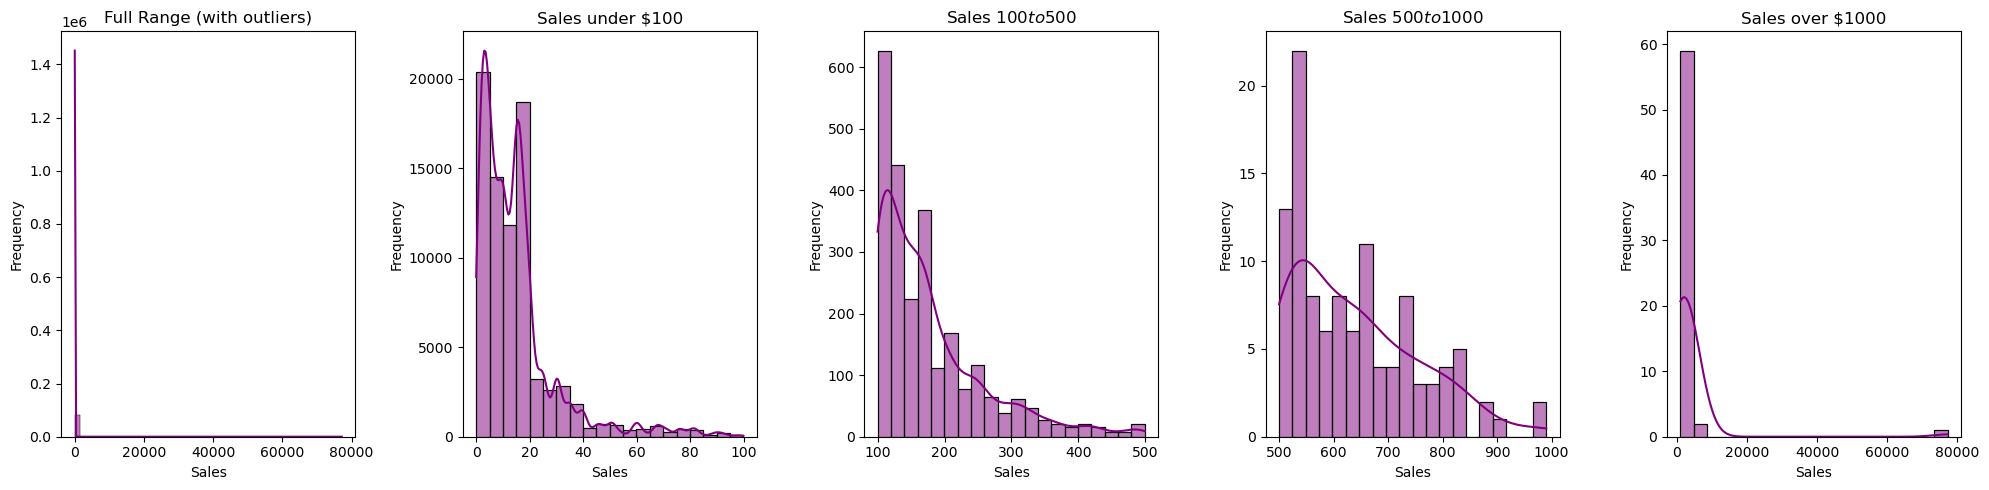

In [24]:
## Histogram Distribution of Sales in Small Ranges of Sales
# By grouping the Sales value into samll ranges it gives more meaningful insights and helps to understand how sales were widely distributed, which also showed the big gaps in sales from less than 10K to nearly 80K sales as per histrogram graph #5 illustrated below.
fig, axes = plt.subplots(1, 5, figsize=(20,5))

sns.histplot(df_filtered['Sales'], bins=50, color='purple', kde=True, ax=axes[0])
axes[0].set_title('Full Range (with outliers)')
axes[0].set_xlabel('Sales')
axes[0].set_ylabel('Frequency')

sns.histplot(df_filtered[df_filtered['Sales'] < 100]['Sales'], bins=20, color='purple', kde=True, ax=axes[1])
axes[1].set_title('Sales under $100')
axes[1].set_xlabel('Sales')
axes[1].set_ylabel('Frequency')

sns.histplot(df_filtered[(df_filtered['Sales'] >= 100) & (df_filtered['Sales'] < 500)]['Sales'], bins=20, color='purple', kde=True, ax=axes[2])
axes[2].set_title('Sales $100 to $500')
axes[2].set_xlabel('Sales')
axes[2].set_ylabel('Frequency')

sns.histplot(df_filtered[(df_filtered['Sales'] >= 500) & (df_filtered['Sales'] < 1000)]['Sales'], bins=20, color='purple', kde=True, ax=axes[3])
axes[3].set_title('Sales $500 to $1000')
axes[3].set_xlabel('Sales')
axes[3].set_ylabel('Frequency')

sns.histplot(df_filtered[df_filtered['Sales'] >= 1000]['Sales'], bins=20, color='purple', kde=True, ax=axes[4])
axes[4].set_title('Sales over $1000')
axes[4].set_xlabel('Sales')
axes[4].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

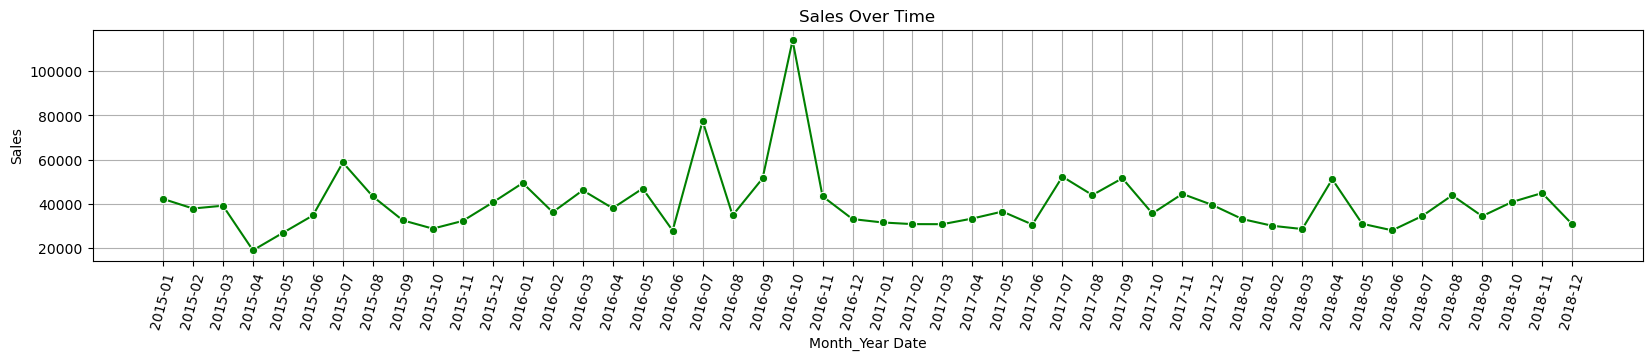

In [25]:
# Line chart to show the trend of Sales over time
plt.figure(figsize=(20,3))
df_sales_month_year = df_filtered.groupby('month_year')['Sales'].sum().reset_index()

sns.lineplot(x='month_year', y='Sales', data=df_sales_month_year, marker='o', color='green')
plt.title('Sales Over Time')
plt.xlabel('Month_Year Date')
plt.ylabel('Sales')
plt.xticks(rotation=75)
plt.grid(True, alpha=1)
plt.show()

##### <u>**Scatter Plot - Relationship Between Quantity and Sales**</u>
##### Based on the visual graph, there is a positive relationship between the quantity and sales, with most transaction were clustered at below $10,000. One most outlier stands out sitting far from the rest which involving a single transaction with a total sales of $77,183.60 and total quantity of 74,215.
 

##### <u>**Histogram - Distribution of Sales**</u>
##### The graph shows that the distribution of sales is heavily right-skewed, with the vast majority of transactions valued under $20 (to be exact, 75% of sales transactions are $19.50 as showed in the describe result(task 4 #1)) and very few exceeding to $100 of sales transactions. Breaking the data into small ranges revealed a secondary concentration of values that was invisible in the full-range of histogram, due to the dominance of the most outliers.

##### <u>**Line Chart - Sales Over Time**</u>
##### The chart shows that the monthly sales fluctuate across the period but the trend generally upward, which the peaking point is in October 2016 with the total sales above $100,000 (or $114,071.05 to be exact). The lowest point occurred in April 2015, with the total sales below $20,000 (or $18,894.97 to be exact) which representing the slowest month in the dataset.

#### **6. Correlation and Data Insights**
##### Objective: Identify the relationship between different numerical columns in the dataset.


In [26]:
## Correlation between Quantity and Sales
correlation = df_filtered[['Quantity', 'Sales']].corr()

print(correlation)

          Quantity     Sales
Quantity  1.000000  0.978609
Sales     0.978609  1.000000


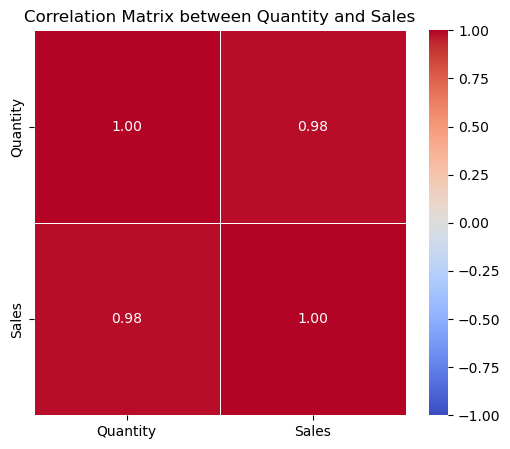

In [27]:
# Create Heatmap for the correlation matrix
plt.figure(figsize=(6,5))
sns.heatmap(correlation, annot=True,cmap='coolwarm', fmt ='.2f', linewidths=0.5,vmin=-1, vmax=1)
plt.title('Correlation Matrix between Quantity and Sales')
plt.show()

##### <u>**Heatmap Matrix - Correlation Between Quantity and Sales**</u>
##### The heatmap shows a very strong positive correlation (0.98) between Quantity and Sales. It is expected since Sales is calculated by multiplying the Quantity by Unit Price, this means as Quantity increases, Sales will also increase.

#### **7. Grouping and Aggregating**
##### Objective: Perform grouping and aggregation operations to summarise the data.

In [28]:
##Group by Product Category and calculate the total Sales per category
sales_by_category = df_filtered.groupby('Product_Category')['Sales'].sum().reset_index()
sales_by_category = sales_by_category.sort_values(by='Sales',ascending = False)

#Display the grouped data
display(sales_by_category)


In [29]:
#Checking the Unique Country Names 
sorted(df_filtered['Country'].unique())

['AUS',
 'Australia',
 'Austria',
 'Bahrain',
 'Belgium',
 'Brazil',
 'Canada',
 'Channel Islands',
 'Cyprus',
 'Czech Republic',
 'Denmark',
 'European Community',
 'Finland',
 'France',
 'Germany',
 'Greece',
 'Iceland',
 'Israel',
 'Italy',
 'Japan',
 'Lebanon',
 'Lithuania',
 'Malta',
 'Netherlands',
 'New Zealand',
 'Norway',
 'Poland',
 'Portugal',
 'RSA',
 'Saudi Arabia',
 'Singapore',
 'Spain',
 'Sweden',
 'Switzerland',
 'USA',
 'United Arab Emirates',
 'United Kingdom',
 'Unspecified']

In [30]:
#Replace AUS to Australia 
df_filtered['Country'] = df_filtered['Country'].replace('AUS', 'Australia')

In [31]:
#Create a pivot table for Sales by Country and ProductCategory and fill NA to 0
pivot_table = df_filtered.pivot_table(values='Sales', index='Country', columns='Product_Category', aggfunc='sum', fill_value=0)

#Reset the index to make Country a normal column
pivot_table = pivot_table.reset_index()

#Display the pivot table
display(pivot_table)

In [32]:
##Group by Country and calculate the total Sales per Country 
sales_by_country = df_filtered.groupby('Country')['Sales'].sum().reset_index()
sales_by_country = sales_by_country.sort_values(by='Sales',ascending = False)

#Display the grouped data
display(sales_by_country.head())


##### I have performed grouping and aggregating to summarized data and show the total sales by product category and by country. I took extra steps on checking and cleaning the data like replacing word "AUS" to Australia and filling NA to 0, which makes the data in the table clean and easy to read. 

 ##### The table shows that Uncategorized products generated the highest sales at $191,282.70, followed by Christmas ($88,028.94) and Candles ($83,853.88). All remaining categories each recorded less than $80,000.
 ##### Because the Uncategorized products has the largest share in the revenue and we cannot identify the specific product type,these products should be reviewed and assigned to appropriate categories so that the future category-level analysis is reliable.

##### Sales by Country - <u>United Kingdom </u>is the leading country with the highest total sales of $1,732,491.93 followed by <u>Germany</u> with total sales of $55,571.41 and all the remaining counties each recorded less than $50,000